<a href="https://colab.research.google.com/github/leovarconrenno/Estacao-de-Reabastecimento-de-Hidrogenio---SCADA-Core/blob/main/etapa-03-arvores/Aula%2022%20-%20Rapidly-exploring%20Random%20Trees%20-%20code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aula 22 - Notebook: Planejamento de Abastecimento SAE J2601 via RRT (SCADA H₂)

Este notebook implementa o algoritmo **Kinodynamic RRT** para sintetizar uma rampa segura de abastecimento de $50\text{ bar}$ até $700\text{ bar}$ no dispensador `DISP-300`, coordenando o chiller `HEX-201` (`TT-201 <= -40 °C`) e o chaveamento em cascata `TK-101` (LP) $\to$ `TK-102` (MP) $\to$ `TK-103` (HP) via válvula direcional `XV-104`.

In [1]:
import time
from typing import List, Tuple, Dict, Optional
import numpy as np
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120
np.random.seed(7)
print("Ambiente RRT carregado para a Estação HRS.")

Ambiente RRT carregado para a Estação HRS.


### 1. Barreira Lógica SIS (Etapa 01) e Dinâmica Térmica-Hidráulica

In [2]:
def avaliar_sis_hrs(x: np.ndarray, at_301_lie: float = 2.0, esd_100: int = 0) -> Tuple[bool, str]:
    """Avalia predicados booleanos da Etapa 01 e SAE J2601: x = [PT_301_bar, TT_301_degC, TT_201_degC]."""
    pt_301, tt_301, tt_201 = x
    if esd_100 == 1:
        return False, "ESD-100 Acionado"
    if at_301_lie > 25.0:
        return False, "AT-301 Vazamento > 25% LIE"
    if pt_301 > 875.0:
        return False, "Sobrepressao PT-301 > 875 bar"
    if tt_301 > 85.0:
        return False, "Sobretemperatura TT-301 > 85 C"
    if tt_301 < -40.0 or tt_201 < -45.0:
        return False, "Subtemperatura Critica < -40 C"
    return True, "OK"

def estagio_cascata_xv104(pt_301: float) -> str:
    if pt_301 < 350.0:
        return "LP (TK-101)"
    if pt_301 < 650.0:
        return "MP (TK-102)"
    return "HP (TK-103)"

def dinamica_dispensacao(x: np.ndarray, u: np.ndarray, dt: float = 1.5) -> np.ndarray:
    pt_301, tt_301, tt_201 = x
    aprr, tt_201_sp = u
    dp = aprr * dt
    tt_201_next = tt_201 + 0.35 * (tt_201_sp - tt_201)
    # Aquecimento por compressao adiabatica + efeito Joule-Thomson negativo mitigado pelo HEX-201
    aq_compressao = 0.19 * dp
    resfriamento = 0.010 * (tt_301 - tt_201_next) * dt
    tt_301_next = tt_301 + aq_compressao - resfriamento
    return np.array([pt_301 + dp, tt_301_next, tt_201_next], dtype=float)

### 2. Algoritmo RRT Híbrido (`XV-104` + `HEX-201` + `DISP-300`)

In [3]:
ESCALAS = np.array([750.0, 85.0, 60.0])

def metrica_hibrida(za: Tuple[np.ndarray, str], zb: Tuple[np.ndarray, str], lam: float = 0.08) -> float:
    d_cont = np.linalg.norm((za[0] - zb[0]) / ESCALAS)
    d_disc = 1.0 if za[1] != zb[1] else 0.0
    return float(d_cont + lam * d_disc)

CONTROLES_HRS = [
    np.array([4.0, -40.0]),  # Rampa rapida + Chiller HEX-201 a -40 C
    np.array([2.5, -40.0]),  # Rampa moderada + Chiller -40 C
    np.array([1.2, -40.0]),  # Rampa conservadora para controle termico
    np.array([7.5, -5.0]),   # Rampa agressiva sem pre-resfriamento pleno (tende a violar 85 C)
]

def executar_rrt_hrs(x_inicial: np.ndarray, p_alvo: float = 700.0, k_max: int = 1000, p_goal: float = 0.10):
    vertices = [(x_inicial, estagio_cascata_xv104(x_inicial[0]))]
    pais: Dict[int, Optional[int]] = {0: None}
    descartados_sis = 0

    for k in range(k_max):
        if np.random.rand() < p_goal:
            x_rand = np.array([np.random.uniform(700.0, 720.0), np.random.uniform(25.0, 78.0), np.random.uniform(-40.0, -35.0)])
        else:
            x_rand = np.array([np.random.uniform(50.0, 820.0), np.random.uniform(20.0, 105.0), np.random.uniform(-42.0, 0.0)])
        z_rand = (x_rand, estagio_cascata_xv104(x_rand[0]))

        idx_near = min(range(len(vertices)), key=lambda i: metrica_hibrida(vertices[i], z_rand))
        x_near, _ = vertices[idx_near]

        # STEER: escolher controle que melhor aproxima z_rand
        melhor_u = min(
            CONTROLES_HRS,
            key=lambda u: metrica_hibrida(
                (dinamica_dispensacao(dinamica_dispensacao(dinamica_dispensacao(x_near, u), u), u), estagio_cascata_xv104(x_near[0])),
                z_rand
            )
        )

        # COLLISION_FREE: verificar subpassos contra barreira SIS (TT-301 <= 85 C)
        x_curr = x_near.copy()
        seguro = True
        for _ in range(3):
            x_curr = dinamica_dispensacao(x_curr, melhor_u)
            ok, _ = avaliar_sis_hrs(x_curr)
            if not ok:
                seguro = False
                break
        if not seguro:
            descartados_sis += 1
            continue

        z_new = (x_curr, estagio_cascata_xv104(x_curr[0]))
        novo_idx = len(vertices)
        vertices.append(z_new)
        pais[novo_idx] = idx_near

        if z_new[0][0] >= p_alvo and z_new[0][1] <= 85.0:
            caminho = []
            curr = novo_idx
            while curr is not None:
                caminho.append(curr)
                curr = pais[curr]
            caminho.reverse()
            return vertices, pais, caminho, k + 1, descartados_sis

    return vertices, pais, None, k_max, descartados_sis

x0 = np.array([50.0, 38.0, 10.0])  # Tanque pre-aquecido ao sol (38 C) e chiller partindo de 10 C
t0 = time.perf_counter()
vertices, pais, caminho, iters, descartados = executar_rrt_hrs(x0)
print(f"Iterações: {iters} | Tempo: {(time.perf_counter()-t0)*1000:.2f} ms | Vértices: {len(vertices)} | Ramos rejeitados pelo SIS: {descartados}")
if caminho is not None:
    traj = np.array([vertices[i][0] for i in caminho])
    estagios = [vertices[i][1] for i in caminho]
    print(f"Trajetória segura encontrada ({len(caminho)} passos): PT-301={traj[-1,0]:.1f} bar | TT-301={traj[-1,1]:.1f} °C | TT-201={traj[-1,2]:.1f} °C")
    print("Sequência de bancos em XV-104:", " -> ".join(dict.fromkeys(estagios)))

Iterações: 179 | Tempo: 169.86 ms | Vértices: 176 | Ramos rejeitados pelo SIS: 4
Trajetória segura encontrada (30 passos): PT-301=716.4 bar | TT-301=50.8 °C | TT-201=-40.0 °C
Sequência de bancos em XV-104: LP (TK-101) -> MP (TK-102) -> HP (TK-103)


### 3. Visualização: Árvore RRT e Comparação com Rampa Direta sem `HEX-201`

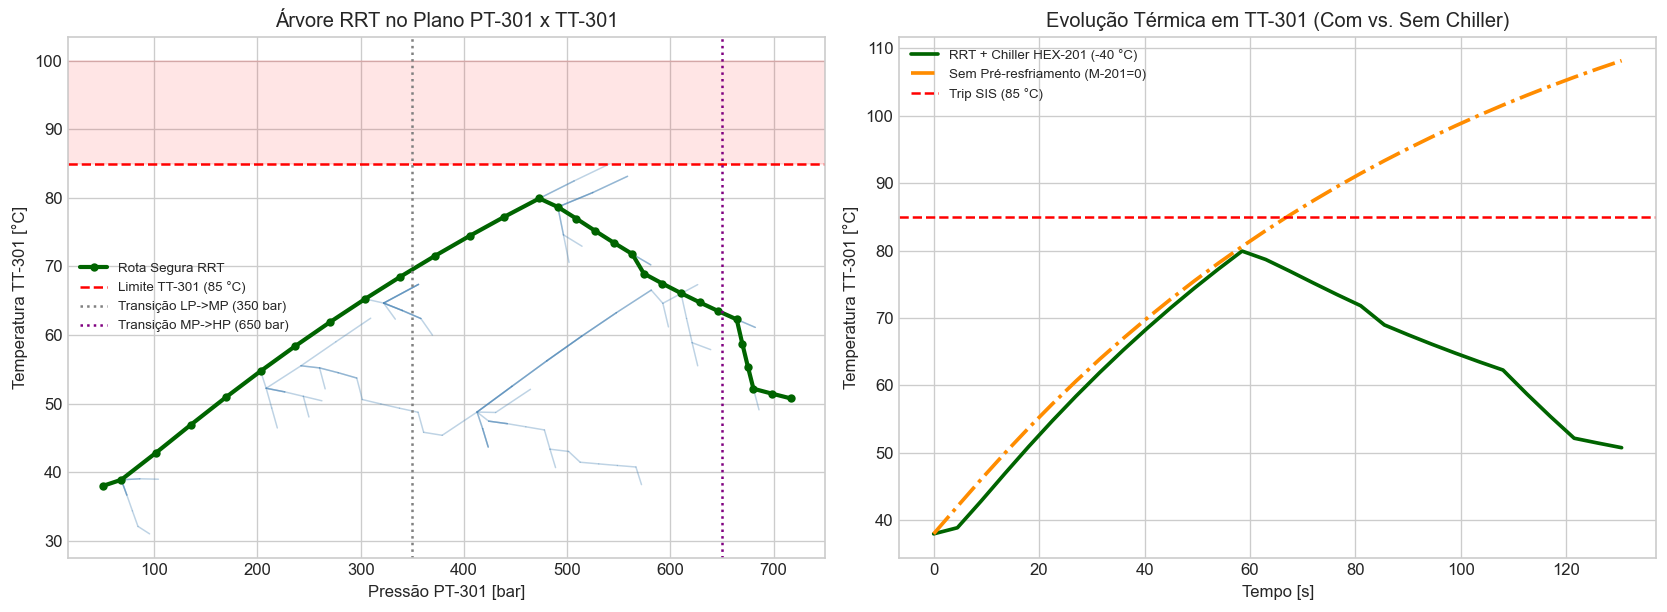

In [4]:
if caminho is not None:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
    ax = axes[0]
    for idx, p_idx in pais.items():
        if p_idx is not None:
            x1, x2 = vertices[p_idx][0], vertices[idx][0]
            ax.plot([x1[0], x2[0]], [x1[1], x2[1]], color="steelblue", alpha=0.35, linewidth=0.9)
    ax.plot(traj[:, 0], traj[:, 1], color="darkgreen", linewidth=2.5, marker="o", markersize=4, label="Rota Segura RRT")
    ax.axhline(85.0, color="red", linestyle="--", label="Limite TT-301 (85 °C)")
    ax.axhspan(85.0, 100.0, color="red", alpha=0.1)
    ax.axvline(350.0, color="gray", linestyle=":", label="Transição LP->MP (350 bar)")
    ax.axvline(650.0, color="purple", linestyle=":", label="Transição MP->HP (650 bar)")
    ax.set_title("Árvore RRT no Plano PT-301 x TT-301")
    ax.set_xlabel("Pressão PT-301 [bar]")
    ax.set_ylabel("Temperatura TT-301 [°C]")
    ax.legend(fontsize=8)

    ax2 = axes[1]
    x_ab = x0.copy()
    traj_ab = [x_ab.copy()]
    for _ in range(len(caminho) - 1):
        for _ in range(3):
            x_ab = dinamica_dispensacao(x_ab, np.array([6.0, 20.0]))
        traj_ab.append(x_ab.copy())
    traj_ab = np.array(traj_ab)
    t_eixo = np.arange(len(traj)) * 4.5
    ax2.plot(t_eixo, traj[:, 1], color="darkgreen", linewidth=2.2, label="RRT + Chiller HEX-201 (-40 °C)")
    ax2.plot(t_eixo, traj_ab[:, 1], color="darkorange", linestyle="-.", linewidth=2.2, label="Sem Pré-resfriamento (M-201=0)")
    ax2.axhline(85.0, color="red", linestyle="--", label="Trip SIS (85 °C)")
    ax2.set_title("Evolução Térmica em TT-301 (Com vs. Sem Chiller)")
    ax2.set_xlabel("Tempo [s]")
    ax2.set_ylabel("Temperatura TT-301 [°C]")
    ax2.legend(fontsize=8)
    plt.tight_layout()
    plt.show()
else:
    print("RRT não convergiu no limite K_max.")